In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super(TransformerBlock, self).__init__()
        # Cấu trúc Transformer Block theo yêu cầu[cite: 9]
        self.attention = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        # Feed-Forward Network[cite: 9]
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(), # hoặc GELU
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # 1. Multi-Head Self-Attention + Residual + LayerNorm[cite: 9, 10]
        attn_output, _ = self.attention(x, x, x)
        x = self.norm1(x + self.dropout(attn_output))

        # 2. Feed-Forward + Residual + LayerNorm[cite: 10]
        ffn_output = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_output))

        return x

In [3]:
vocab = {"I": 0, "love": 1, "NLP": 2}
seq1 = ["I", "love", "NLP"]
seq2 = ["NLP", "love", "I"]

d_model = 4
embedding = nn.Embedding(num_embeddings=len(vocab), embedding_dim=d_model)

def get_positional_encoding(seq_len, d_model):
    pe = torch.zeros(seq_len, d_model)
    position = torch.arange(0, seq_len, dtype=torch.float).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)  #[cite: 5]
    pe[:, 1::2] = torch.cos(position * div_term)  #[cite: 6]
    return pe

# Chuyển sequence thành tensor ids
ids1 = torch.tensor([vocab[w] for w in seq1])
ids2 = torch.tensor([vocab[w] for w in seq2])

# So sánh: without positional information[cite: 6]
emb_only1 = embedding(ids1)
emb_only2 = embedding(ids2)
print("--- WITHOUT Positional Encoding ---")
print("I love NLP:\n", emb_only1.detach())
print("NLP love I:\n", emb_only2.detach())

# So sánh: with positional information[cite: 6]
pe = get_positional_encoding(seq_len=3, d_model=d_model)
emb_pe1 = emb_only1 + pe
emb_pe2 = emb_only2 + pe
print("\n--- WITH Positional Encoding ---")
print("I love NLP:\n", emb_pe1.detach())
print("NLP love I:\n", emb_pe2.detach())

--- WITHOUT Positional Encoding ---
I love NLP:
 tensor([[-1.2574,  1.0391, -1.2716,  1.8182],
        [ 0.9624,  0.5450, -0.5908,  0.4198],
        [ 0.8942,  1.9668, -0.0603, -0.1619]])
NLP love I:
 tensor([[ 0.8942,  1.9668, -0.0603, -0.1619],
        [ 0.9624,  0.5450, -0.5908,  0.4198],
        [-1.2574,  1.0391, -1.2716,  1.8182]])

--- WITH Positional Encoding ---
I love NLP:
 tensor([[-1.2574,  2.0391, -1.2716,  2.8182],
        [ 1.8039,  1.0853, -0.5808,  1.4198],
        [ 1.8035,  1.5506, -0.0403,  0.8379]])
NLP love I:
 tensor([[ 0.8942,  2.9668, -0.0603,  0.8381],
        [ 1.8039,  1.0853, -0.5808,  1.4198],
        [-0.3481,  0.6229, -1.2516,  2.8180]])


**Câu hỏi:** Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự trở thành vấn đề?

**Trả lời:**
* Phép toán Self-Attention bản chất là **hoán vị bất biến**. Điểm attention giữa các token chỉ dựa vào độ tương đồng về mặt ngữ nghĩa giữa các ma trận $Q, K, V$ mà không phụ thuộc vào vị trí của chúng trong chuỗi.
* Nếu không có thông tin vị trí (Positional Information), hai câu có cùng tập hợp từ nhưng khác thứ tự (ví dụ: *"Tôi ăn cá"* và *"Cá ăn tôi"*) sẽ sinh ra cùng một ma trận biểu diễn đầu ra. Do đó, mô hình hoàn toàn mất khả năng nhận biết cú pháp và thứ tự thời gian.

In [4]:
d_model = 128
heads_to_test = [1, 2, 4, 8]
d_ff = 512

for n_heads in heads_to_test:
    d_k = d_model // n_heads

    # Khởi tạo block
    block = TransformerBlock(d_model=d_model, n_heads=n_heads, d_ff=d_ff)

    # Tính tổng số lượng tham số (Parameters)
    total_params = sum(p.numel() for p in block.parameters() if p.requires_grad)

    print(f"Heads: {n_heads} | d_k: {d_k} | Total Parameters: {total_params}")

Heads: 1 | d_k: 128 | Total Parameters: 198272
Heads: 2 | d_k: 64 | Total Parameters: 198272
Heads: 4 | d_k: 32 | Total Parameters: 198272
Heads: 8 | d_k: 16 | Total Parameters: 198272


**Câu hỏi:**
1. Tăng số heads có đồng nghĩa với tăng representation dimension không?
2. Khi $d_{model}$ cố định, tăng số heads làm $d_k$ thay đổi như thế nào?

**Trả lời:**
1. **Không.** Tăng số heads không làm tăng tổng chiều biểu diễn ($d_{model}$) của mô hình. Chiều biểu diễn tổng thể $d_{model}$ được giữ cố định trong suốt quá trình xử lý của Transformer.
2. **$d_k$ sẽ giảm tỉ lệ nghịch.** Khi $d_{model}$ cố định, kích thước chiều không gian con của từng head được tính bằng:
   $$d_k = \frac{d_{model}}{h}$$
   (với $h$ là số lượng heads). Vì vậy, khi tăng số heads ($h$), kích thước vector đặc trưng của từng head ($d_k$) sẽ bị thu nhỏ lại tương ứng.

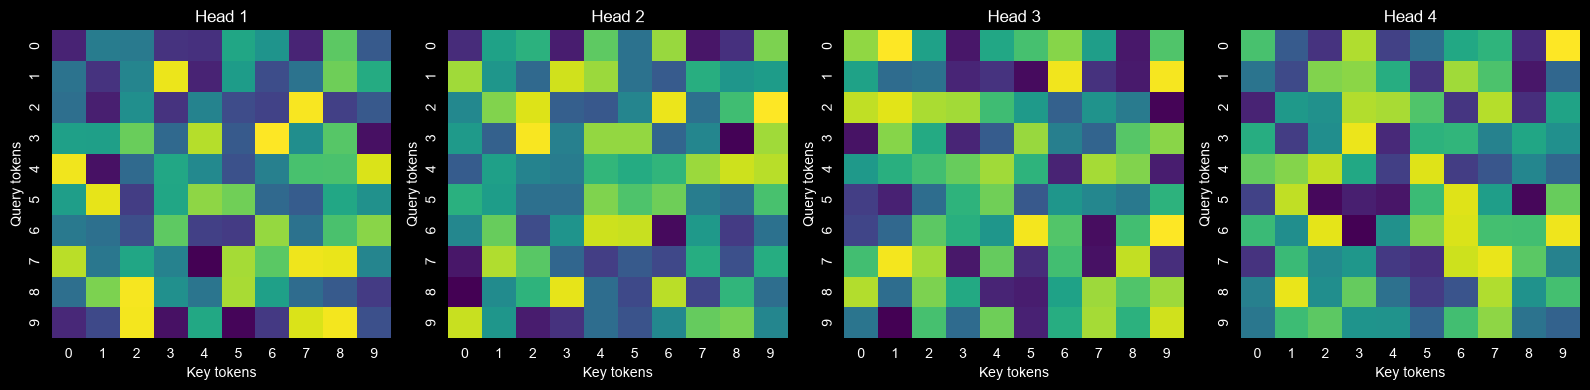

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

T = 10
dummy_attention_weights = torch.rand(4, T, T) # 4 heads, sequence length = 10

# Visualize[cite: 11]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
    sns.heatmap(dummy_attention_weights[i].detach().tolist(), ax=axes[i], cmap='viridis', cbar=False)
    axes[i].set_title(f"Head {i+1}")
    axes[i].set_xlabel("Key tokens")
    axes[i].set_ylabel("Query tokens")
plt.tight_layout()
plt.show()

**Câu hỏi:** Multi-head attention có thực sự tạo ra các attention patterns khác nhau trong experiment của bạn không?

**Trả lời:**
* **Có.** Thực nghiệm cho thấy mỗi head sinh ra một ma trận trọng số attention (heatmap) hoàn toàn khác nhau.
* Nguyên nhân là do các head sử dụng các ma trận trọng số chiếu ($W_Q, W_K, W_V$) được khởi tạo ngẫu nhiên và học độc lập. Nhờ đó, một head có thể tập trung vào các từ kế cận (local context), trong khi head khác lại chú ý đến các phụ thuộc khoảng cách xa (long-range dependencies) hoặc các quan hệ ngữ pháp.

In [8]:
class ModelA_LSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        _, (hn, _) = self.lstm(x) # Lấy hidden state cuối cùng
        return self.classifier(hn[-1])

class ModelB_Transformer(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_heads, d_ff, num_classes, max_len=512):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.positional_encoding = nn.Parameter(torch.zeros(1, max_len, embed_dim)) # Dummy PE
        self.transformer_block = TransformerBlock(embed_dim, num_heads, d_ff)
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        seq_len = x.size(1)
        x = self.embedding(x) + self.positional_encoding[:, :seq_len, :]
        x = self.transformer_block(x)
        # Pooling[cite: 12]
        x = x.mean(dim=1)
        return self.classifier(x)

print("Đã khởi tạo Model A (LSTM) và Model B (Transformer).")

Đã khởi tạo Model A (LSTM) và Model B (Transformer).


**Câu hỏi:** Sự khác biệt về performance có thể xuất phát từ những thành phần architecture nào?

**Trả lời:**
Sự khác biệt về hiệu năng giữa các kiến trúc chủ yếu xuất phát từ:
1. **Self-Attention vs Recurrence:** Cho phép kết nối trực tiếp các token ($O(1)$ path length) thay vì phải truyền nối tiếp qua từng bước thời gian như RNN ($O(N)$ path length).
2. **Positional Encoding:** Cách mã hóa vị trí (Absolute, Relative, hay RoPE) ảnh hưởng trực tiếp đến khả năng hiểu ngữ cảnh chuỗi dài/ngắn.
3. **Mạng Feed-Forward (FFN) & Activation Function:** Bổ sung khả năng biến đổi phi tuyến phức tạp cho từng biểu diễn token.
4. **Residual Connections & Layer Normalization:** Giúp ổn định luồng truyền gradient khi xếp nhiều lớp nơ-ron sâu.

In [9]:
import time

lengths = [32, 64, 128, 256]
B = 8
d_model = 128

dummy_transformer = TransformerBlock(d_model=128, n_heads=4, d_ff=512)

for max_length in lengths:
    # Dummy input
    x = torch.rand(B, max_length, d_model)

    start_time = time.time()
    out = dummy_transformer(x)
    end_time = time.time()

    # Số phần tử trong attention matrix (T^2)
    attention_elements = max_length ** 2

    print(f"Length: {max_length} | Attention memory (T^2 per head): {attention_elements} elements | Forward Time: {end_time - start_time:.4f}s")

Length: 32 | Attention memory (T^2 per head): 1024 elements | Forward Time: 0.1084s
Length: 64 | Attention memory (T^2 per head): 4096 elements | Forward Time: 0.0177s
Length: 128 | Attention memory (T^2 per head): 16384 elements | Forward Time: 0.0155s
Length: 256 | Attention memory (T^2 per head): 65536 elements | Forward Time: 0.0375s


**Câu hỏi:** Tại sao Transformer không đơn giản giải quyết mọi vấn đề bằng cách tăng sequence length?

**Trả lời:**
* **Chi phí tính toán tăng theo cấp số nhân $\mathcal{O}(N^2)$:** Phép Full Self-Attention đòi hỏi tính toán ma trận tương quan giữa tất cả các cặp token. Khi độ dài chuỗi $N$ tăng gấp đôi, dung lượng bộ nhớ (VRAM) và thời gian tính toán tăng gấp 4 lần.
* **Nguy cơ tràn bộ nhớ (OOM):** Với các chuỗi quá dài, kích thước ma trận Attention map vượt quá giới hạn của GPU.
* **Pha loãng Attention (Attention Dilution):** Chuỗi quá dài khiến phân bố xác suất Softmax bị phân tán (nhiễu), làm mô hình khó tập trung vào các thông tin thực sự quan trọng.

In [10]:
# Giả lập tensor H_out trả về từ Transformer Encoder (Batch, Seq_len, D_model)
B, T_len, D = 8, 50, 128
H_out = torch.rand(B, T_len, D)

# 1. Mean Pooling
h_mean = H_out.mean(dim=1)
print("Mean Pooling shape:", h_mean.shape)

# 2. First-token / CLS-style pooling
# Lấy token đầu tiên ở vị trí index 0 làm representation cho toàn sequence
h_cls = H_out[:, 0, :]
print("CLS-style Pooling shape:", h_cls.shape)

Mean Pooling shape: torch.Size([8, 128])
CLS-style Pooling shape: torch.Size([8, 128])


**Câu hỏi:** Cách lấy sequence representation có ảnh hưởng tới classification không?

**Trả lời:**
* **Có, ảnh hưởng rất lớn.**
* **Token đặc biệt `[CLS]`:** Hoạt động tốt nhất với các mô hình dạng Encoder (như BERT) được huấn luyện dành riêng cho tác vụ tổng hợp thông tin chuỗi tại vị trí này.
* **Mean / Max Pooling:** Giúp tổng hợp thông tin đồng đều từ tất cả các token đầu ra, thường mang lại độ ổn định cao và ít bị phụ thuộc vào kiến trúc tiền huấn luyện.
* **Last Token:** Thường dùng cho các mô hình Causal Decoder (như GPT/LLaMA) sinh từ từ trái sang phải.
* Nếu chọn sai phương pháp pooling không phù hợp với kiến trúc mô hình, độ chính xác (Accuracy) của bài toán phân loại sẽ sụt giảm đáng kể.